koneksi dengan google drive untuk akses dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#libarry yang di gunakan
import pandas as pd
import numpy as np

In [ ]:
#cek datasetnya
df = pd.read_csv("/content/drive/MyDrive/Data Penjualan UMKM for AI Agent/indonesia_ecommerce_sales_challenging.csv", sep=";")
df.head()

,order_id,total_qty,total_weight_gr,total_returned_qty,Total Diskon,product_categories,num_product_categories,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Metode Pembayaran,Kota/Kabupaten,Provinsi,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Waktu Pesanan Dibuat,order_date
0,ORD_0000001,2.0,2000,0,0,Celengan,1,Selesai,Tidak dibatalkan,Reguler (Cashless)-SPX Standard,Saldo ShopeePay,KOTA SERANG,BANTEN,0,10000,38300,10000,2024-04-01 00:15,2024-04-01
1,ORD_0000002,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA SEMARANG,JAWA TENGAH,0,14500,18576,14500,2024-04-01 01:47,2024-04-01
2,ORD_0000003,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,SeaBank Bayar Instan,KAB. BOGOR,JAWA BARAT,0,8000,7069,8000,2024-04-01 04:25,2024-04-01
3,ORD_0000004,2.0,400,0,0,Mangkok Sambal / Saus,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA JAMBI,JAMBI,0,20000,32200,20000,2024-04-01 04:41,2024-04-01
4,ORD_0000005,3.0,3600,0,0,"Keranjang, Other, Tempat Nasi",3,Batal,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA TANGERANG,BANTEN,0,0,0,8000,2024-04-01 06:12,2024-04-01


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18868 entries, 0 to 18867
Data columns (total 19 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   order_id                            18868 non-null  object 
 1   total_qty                           18585 non-null  float64
 2   total_weight_gr                     18868 non-null  int64  
 3   total_returned_qty                  18868 non-null  int64  
 4   Total Diskon                        18868 non-null  int64  
 5   product_categories                  18868 non-null  object 
 6   num_product_categories              18868 non-null  int64  
 7   Status Pesanan                      18868 non-null  object 
 8   Alasan Pembatalan                   18868 non-null  object 
 9   Opsi Pengiriman                     18868 non-null  object 
 10  Metode Pembayaran                   18585 non-null  object 
 11  Kota/Kabupaten                      18868

In [ ]:
#cek missing value makek isnul
missing = df.isnull().sum()
#missing
print("\nMissing Values:")
print(missing[missing > 0])


Missing Values:
total_qty            283
Metode Pembayaran    283
order_date           188
dtype: int64


In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,18868,18868,ORD_0000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_qty,18585.0,NaN,NaN,NaN,2.56594,7.799706,1.0,1.0,1.0,2.0,256.0
total_weight_gr,18868.0,NaN,NaN,NaN,2021.273055,7044.934507,10.0,300.0,500.0,1600.0,375000.0
total_returned_qty,18868.0,NaN,NaN,NaN,0.018709,0.575668,0.0,0.0,0.0,0.0,70.0
Total Diskon,18868.0,NaN,NaN,NaN,424.220691,10110.49275,0.0,0.0,0.0,0.0,700000.0
product_categories,18868,640,Celengan,5083,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_product_categories,18868.0,NaN,NaN,NaN,1.113473,0.491409,1.0,1.0,1.0,1.0,11.0
Status Pesanan,18868,11,Selesai,16045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Alasan Pembatalan,18868,19,Tidak dibatalkan,16295,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Opsi Pengiriman,18868,45,Hemat Kargo-SPX Hemat,11571,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
display(
    df[df["total_qty"].isna()][
        ["order_id", "Status Pesanan", "Total Pembayaran"]
    ]["Status Pesanan"].value_counts()
)

,count
Status Pesanan,
Selesai,235
Batal,44
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-08.",2
Telah Dikirim,1
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-09.",1


In [ ]:
display(
    pd.crosstab(
        df["Status Pesanan"],
        df["Metode Pembayaran"].isna(),
        margins=True
    )
)

Metode Pembayaran,False,True,All
Status Pesanan,,,
Batal,2541,32,2573
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-05.",25,0,25
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-06.",34,0,34
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-07.",34,0,34
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-08.",38,0,38
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-09.",22,0,22
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-10.",6,0,6
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-11.",2,0,2
Sedang Dikirim,59,0,59


In [ ]:
# Pastikan kedua kolom bertipe datetime
df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)

df["Waktu Pesanan Dibuat"] = pd.to_datetime(
    df["Waktu Pesanan Dibuat"], errors="coerce"
)

# Periksa baris yang order_date-nya kosong
display(
    df.loc[
        df["order_date"].isna(),
        ["order_id", "Waktu Pesanan Dibuat", "Status Pesanan"]
    ].head(20)
)

,order_id,Waktu Pesanan Dibuat,Status Pesanan
59,ORD_0000060,2024-04-10 13:37:00,Selesai
81,ORD_0000082,2024-04-12 16:15:00,Selesai
84,ORD_0000085,2024-04-12 18:16:00,Selesai
88,ORD_0000089,2024-04-13 02:53:00,Selesai
100,ORD_0000101,2024-04-13 19:51:00,Selesai
137,ORD_0000138,2024-04-15 17:27:00,Selesai
152,ORD_0000153,2024-04-16 10:39:00,Selesai
160,ORD_0000161,2024-04-16 18:13:00,Batal
270,ORD_0000271,2024-04-19 20:26:00,Batal
296,ORD_0000297,2024-04-20 16:40:00,Selesai


In [ ]:
# Menghitung berapa tanggal kosong yang dapat dipulihkan
tanggal_bisa_dipulihkan = (
    df["order_date"].isna() &
    df["Waktu Pesanan Dibuat"].notna()
)

print(
    "Tanggal dapat dipulihkan:",
    tanggal_bisa_dipulihkan.sum()
)

print(
    "Tanggal masih tidak tersedia:",
    (
        df["order_date"].isna() &
        df["Waktu Pesanan Dibuat"].isna()
    ).sum()
)

Tanggal dapat dipulihkan: 593
Tanggal masih tidak tersedia: 0


In [ ]:
# Membuat salinan dataset
df_clean = df.copy()

# Membuat salinan dataset
df_clean = df.copy()

# 1. Memulihkan order_date dari Waktu Pesanan Dibuat
df_clean["order_date"] = df_clean["order_date"].fillna(
    df_clean["Waktu Pesanan Dibuat"]
)

# 2. Mengisi metode pembayaran yang kosong
df_clean["Metode Pembayaran"] = (
    df_clean["Metode Pembayaran"].fillna("Unknown")
)

# 3. Mengisi total_qty dengan median
median_qty = df_clean["total_qty"].median()

df_clean["total_qty"] = df_clean["total_qty"].fillna(median_qty)

print("Median quantity:", median_qty)
print("\nMissing values setelah cleaning:")
print(df_clean.isnull().sum())

Median quantity: 1.0

Missing values setelah cleaning:
order_id                              0
total_qty                             0
total_weight_gr                       0
total_returned_qty                    0
Total Diskon                          0
product_categories                    0
num_product_categories                0
Status Pesanan                        0
Alasan Pembatalan                     0
Opsi Pengiriman                       0
Metode Pembayaran                     0
Kota/Kabupaten                        0
Provinsi                              0
Ongkos Kirim Dibayar oleh Pembeli     0
Estimasi Potongan Biaya Pengiriman    0
Total Pembayaran                      0
Perkiraan Ongkos Kirim                0
Waktu Pesanan Dibuat                  0
order_date                            0
dtype: int64


In [ ]:
# Perbandingan sebelum dan sesudah cleaning
comparison = pd.DataFrame({
    "Before": df.isnull().sum(),
    "After": df_clean.isnull().sum()
})

display(comparison)

,Before,After
order_id,0,0
total_qty,283,0
total_weight_gr,0,0
total_returned_qty,0,0
Total Diskon,0,0
product_categories,0,0
num_product_categories,0,0
Status Pesanan,0,0
Alasan Pembatalan,0,0
Opsi Pengiriman,0,0


In [ ]:
df_clean.to_csv(
    "/content/drive/MyDrive/Data Penjualan UMKM for AI Agent/clean-indonesia_ecommerce_cleaned.csv",
    index=False
)

print("Dataset cleaned berhasil disimpan!")

Dataset cleaned berhasil disimpan!


In [ ]:
# Ringkasan status pesanan
display(
    df_clean["Status Pesanan"]
    .value_counts()
    .to_frame("Jumlah Pesanan")
)

# Statistik penjualan
display(
    df_clean[
        [
            "total_qty",
            "Total Diskon",
            "Total Pembayaran",
            "Ongkos Kirim Dibayar oleh Pembeli"
        ]
    ].describe().T
)

# Tren jumlah pesanan per bulan
df_clean["order_month"] = pd.to_datetime(
    df_clean["order_date"]
).dt.to_period("M")

monthly_orders = (
    df_clean.groupby("order_month")
    .size()
    .reset_index(name="total_orders")
)

display(monthly_orders)

,Jumlah Pesanan
Status Pesanan,
Selesai,16045
Batal,2573
Sedang Dikirim,59
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-08.",38
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-06.",34
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-07.",34
Telah Dikirim,30
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-05.",25
"Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-09.",22


,count,mean,std,min,25%,50%,75%,max
total_qty,18868.0,2.542453,7.743328,1.0,1.0,1.0,2.00,256.0
Total Diskon,18868.0,424.220691,10110.492750,0.0,0.0,0.0,0.00,700000.0
Total Pembayaran,18868.0,50990.661490,142618.930018,0.0,13675.0,21800.0,42311.25,3076000.0
Ongkos Kirim Dibayar oleh Pembeli,18868.0,4312.362678,13900.862394,0.0,0.0,0.0,3000.00,584000.0


,order_month,total_orders
0,2023-12,444
1,2024-01,431
2,2024-02,389
3,2024-03,453
4,2024-04,492
5,2024-05,620
6,2024-06,697
7,2024-07,1270
8,2024-08,1293
9,2024-09,1123


In [ ]:
# Menghitung KPI utama

total_orders = df_clean["order_id"].nunique()

completed_orders = (
    df_clean["Status Pesanan"] == "Selesai"
).sum()

cancelled_orders = (
    df_clean["Status Pesanan"] == "Batal"
).sum()

cancellation_rate = (
    cancelled_orders / total_orders
) * 100

average_order_value = (
    df_clean["Total Pembayaran"].sum() / total_orders
)

average_quantity = (
    df_clean["total_qty"].sum() / total_orders
)

print("===== BUSINESS KPI =====")
print("Total Orders:", total_orders)
print("Completed Orders:", completed_orders)
print("Cancelled Orders:", cancelled_orders)
print("Cancellation Rate:", round(cancellation_rate, 2), "%")
print("Average Order Value: Rp", round(average_order_value, 2))
print("Average Quantity per Order:", round(average_quantity, 2))

===== BUSINESS KPI =====
Total Orders: 18868
Completed Orders: 16045
Cancelled Orders: 2573
Cancellation Rate: 13.64 %
Average Order Value: Rp 50990.66
Average Quantity per Order: 2.54


In [ ]:
# Pastikan order_date bertipe datetime
df_clean["order_date"] = pd.to_datetime(
    df_clean["order_date"]
)

# Membuat kolom bulan
df_clean["order_month"] = (
    df_clean["order_date"].dt.to_period("M")
)

# Agregasi KPI bulanan
monthly_kpi = (
    df_clean.groupby("order_month")
    .agg(
        total_orders=("order_id", "nunique"),
        completed_orders=(
            "Status Pesanan",
            lambda x: (x == "Selesai").sum()
        ),
        cancelled_orders=(
            "Status Pesanan",
            lambda x: (x == "Batal").sum()
        )
    )
    .reset_index()
)

# Cancellation rate bulanan
monthly_kpi["cancellation_rate"] = (
    monthly_kpi["cancelled_orders"]
    / monthly_kpi["total_orders"]
) * 100

display(monthly_kpi)

,order_month,total_orders,completed_orders,cancelled_orders,cancellation_rate
0,2023-12,444,352,92,20.720721
1,2024-01,431,367,64,14.849188
2,2024-02,389,327,62,15.938303
3,2024-03,453,389,64,14.128035
4,2024-04,492,403,89,18.089431
5,2024-05,620,525,95,15.322581
6,2024-06,697,608,89,12.769010
7,2024-07,1270,1114,156,12.283465
8,2024-08,1293,1097,196,15.158546
9,2024-09,1123,967,156,13.891362


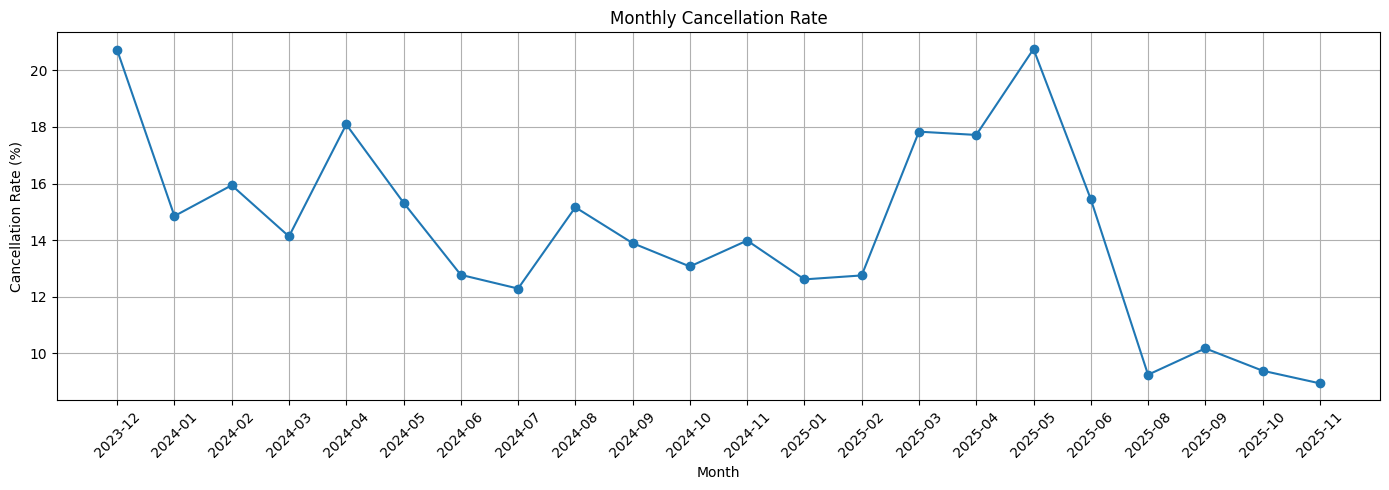

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_kpi["order_month"].astype(str),
    monthly_kpi["cancellation_rate"],
    marker="o"
)

plt.title("Monthly Cancellation Rate")
plt.xlabel("Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#json
import json

business_summary = {
    "project": "UMKM Channel Strategy Advisor",
    "dataset": "Indonesia E-Commerce Sales",
    "total_orders": int(total_orders),
    "completed_orders": int(completed_orders),
    "cancelled_orders": int(cancelled_orders),
    "cancellation_rate": round(
        float(cancellation_rate), 2
    ),
    "average_order_value": round(
        float(average_order_value), 2
    ),
    "average_quantity": round(
        float(average_quantity), 2
    ),
    "monthly_cancellation": [
        {
            "month": str(row["order_month"]),
            "total_orders": int(row["total_orders"]),
            "cancelled_orders": int(row["cancelled_orders"]),
            "cancellation_rate": round(
                float(row["cancellation_rate"]), 2
            )
        }
        for _, row in monthly_kpi.iterrows()
    ]
}

with open(
    "//content/drive/MyDrive/Data Penjualan UMKM for AI Agent/umkm_business_summary.json",
    "w"
) as f:
    json.dump(business_summary, f, indent=4)

print("Business summary berhasil diekspor!")

Business summary berhasil diekspor!
